In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway, levene, shapiro
from statsmodels.stats.multicomp import pairwise_tukeyhsd

np.random.seed(42)

group_a = np.random.normal(loc=65, scale=5, size=30)
group_b = np.random.normal(loc=70, scale=5, size=30)
group_c = np.random.normal(loc=75, scale=5, size=30)

df = pd.DataFrame({
    "score": np.concatenate([group_a, group_b, group_c]),
    "teaching_method": (
        ["Traditional"] * 30
        + ["Online"] * 30
        + ["Blended"] * 30
    )
})

df.head()

,score,teaching_method
0,67.483571,Traditional
1,64.308678,Traditional
2,68.238443,Traditional
3,72.615149,Traditional
4,63.829233,Traditional


In [8]:
df.groupby("teaching_method")["score"].agg(
    ["count", "mean", "std"]
)

,count,mean,std
teaching_method,,,
Blended,30,75.064424,4.959915
Online,30,69.394188,4.655511
Traditional,30,64.059266,4.500032


## One-Way ANOVA: Exam Scores Across Teaching Methods

### Objective
To determine whether the mean exam scores differ across three teaching methods.

### Hypotheses

- **H₀:** All three population mean scores are equal.
- **H₁:** At least one population mean score is different.

Significance level: α = 0.05.

One-Way ANOVA compares the means of three or more independent groups.

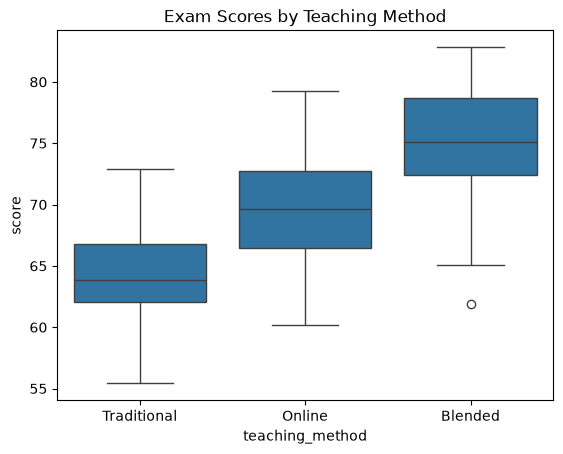

In [9]:
sns.boxplot(data=df, x="teaching_method", y="score")
plt.title("Exam Scores by Teaching Method")
plt.show()

In [14]:
groups = [
    group["score"].values
    for _, group in df.groupby("teaching_method")
]

for name, values in zip(
    df["teaching_method"].unique(), groups
):
    stat, p = shapiro(values)
    print(name, "Shapiro p-value:", round(p, 4))

stat, p = levene(*groups, center="median")
print("Levene p-value:", round(p, 4))

Traditional Shapiro p-value: 0.3654
Online Shapiro p-value: 0.913
Blended Shapiro p-value: 0.6868
Levene p-value: 0.8627


In [11]:
f_stat, p_value = f_oneway(*groups)

print("F-statistic:", round(f_stat, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: At least one group mean differs.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

F-statistic: 40.9756
P-value: 2.8937681350717555e-13
Reject H0: At least one group mean differs.


In [12]:
grand_mean = df["score"].mean()

ss_between = sum(
    len(values) * (values.mean() - grand_mean) ** 2
    for values in groups
)

ss_total = ((df["score"] - grand_mean) ** 2).sum()

eta_squared = ss_between / ss_total

print("Eta-squared:", round(eta_squared, 4))

Eta-squared: 0.4851


If Eta-squared = 0.48, we can say:
“48% of the total variation in the scores is explained by the differences between the teaching-method groups.”The higher the Eta-squared (\(eta^2)), the larger the proportion of variation in scores associated with differences between teaching-method groups.

In [13]:
tukey = pairwise_tukeyhsd(
    endog=df["score"],
    groups=df["teaching_method"],
    alpha=0.05
)

print(tukey)

    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
 group1    group2   meandiff p-adj   lower    upper  reject
-----------------------------------------------------------
Blended      Online  -5.6702    0.0  -8.5694  -2.771   True
Blended Traditional -11.0052    0.0 -13.9044  -8.106   True
 Online Traditional  -5.3349 0.0001  -8.2341 -2.4357   True
-----------------------------------------------------------


all the hypothesis are rejected which means that all the means are significantly different from each other